# Plan 19: Continual PiCar Learning

Can STM regularization save new experience at matched retention and operational cost? Phase 0 is implementation smoke, not evidence of robot capability or sample savings. [Protocol](plan19.md).

In [ ]:
from pathlib import Path
import os, sys
for parent in (Path.cwd(), *Path.cwd().parents):
    if (parent / 'numerical_experiment/picar').is_dir():
        sys.path.insert(0, str(parent))
        break
import pandas as pd
from IPython.display import display
from numerical_experiment.picar import report
ROOT = report.resolve_root('/home/evan/Documents/notebooks/amari-chenstov-updates/cache/numerical_experiment/picar')  # PICAR_CACHE_ROOT overrides the default
snapshot = report.load_report(ROOT)
print(f'Artifacts: {report.root_label(ROOT)} | {snapshot["status"]}')
print(snapshot['note'])
display(pd.DataFrame(report.progress_rows(snapshot)))
if snapshot['live']:
    display(pd.DataFrame(snapshot['live']))
from numerical_experiment.picar.phase3_report import progress_rows as development_progress
from numerical_experiment.picar_initialization.report import historical_phase3_snapshot
development = development_progress(historical_phase3_snapshot(snapshot))
if development:
    display(pd.DataFrame(development))
from numerical_experiment.picar_initialization.report import display_progress
display_progress(snapshot)
from numerical_experiment.picar_solver_repair import report as solver_report
solver_snapshot = solver_report.load_report('/home/evan/Documents/notebooks/amari-chenstov-updates/cache/numerical_experiment/picar/phase3/solver-fix2-v3')
solver_report.display_progress(solver_snapshot)

Artifacts: cache/numerical_experiment/picar | available


Readiness and resource probes describe implementation and operating cost; learning results require fresh paired trajectories.


phase,stage,completed_units,diagnostics,incomplete_units,stopped_units,diagnostic_failures,scientific_units,completed_active_s,status
0,Implementation and acceptance,13,5,0,0,0,0,195.684829,artifacts available
1,Physical/resource readiness,154,0,4,4,0,0,7256.737405,artifacts available; stopped attempts retained
2,Bootstrap and student readiness,24,0,0,0,0,1,11691.744591,artifacts available
3,Development and retention matching,80,0,4,2,0,0,46843.235604,recorded solver comparison
4,Fresh paired learning,0,0,0,0,0,0,NaN,pending
5,Efficiency and closeout,0,0,0,0,0,0,NaN,pending


path,phase,status,counts,updated_at,stopped
/home/evan/Documents/notebooks/amari-chenstov-updates/cache/numerical_experiment/picar/phase1/fix2-v1/orchestration,1,Fix 2 checkpointed; explicit resume required,{'step': 20},None,True
/home/evan/Documents/notebooks/amari-chenstov-updates/cache/numerical_experiment/picar/phase1/fix2-v1/units/pipeline-020281bed68c,1,Fix 2 replay_ewc pipeline starting,{'step': 0},None,True
/home/evan/Documents/notebooks/amari-chenstov-updates/cache/numerical_experiment/picar/phase1/fix3-v1/orchestration,1,Fix 3 checkpointed; explicit --resume required,"{'step': 8, 'target': 23}",None,True
/home/evan/Documents/notebooks/amari-chenstov-updates/cache/numerical_experiment/picar/phase1/fix3-v1/units/teacher-2009a6d4bb5f,1,Fix 3 teacher ported,{'step': 16},None,True
/home/evan/Documents/notebooks/amari-chenstov-updates/cache/numerical_experiment/picar/phase3/solver-fix2-v1/orchestration,3,checkpointed: InterruptedError,{},None,True
/home/evan/Documents/notebooks/amari-chenstov-updates/cache/numerical_experiment/picar/phase3/solver-fix2-v1/units/recorded-e80c418e1dcd,3,recorded solver comparison,"{'step': 88, 'target': 128}",None,True
/home/evan/Documents/notebooks/amari-chenstov-updates/cache/numerical_experiment/picar/phase3/solver-fix2-v2/orchestration,3,checkpointed: ValueError,{},None,False
/home/evan/Documents/notebooks/amari-chenstov-updates/cache/numerical_experiment/picar/phase3/solver-fix2-v2/units/recorded-9813bb3e40e0,3,recorded solver comparison,"{'step': 8, 'target': 128}",None,False


Campaign,Status,Completed trajectories,Active unit,Active progress,Budget remaining (s),Remaining estimate (s),Phase 3 active (s),Study charge (s),Unit progress,Sealed units
solver-fix2-v1,stopped,0.0,recorded-e80c418e1dcd,recorded solver comparison: 88/128,31771.987534,None,NaN,65109.421542,88/128,0
solver-fix2-v2,recorded solver comparison,0.0,recorded-9813bb3e40e0,recorded solver comparison: 8/128,30958.494341,None,NaN,65922.914734,8/128,0
development-v1,stopped,NaN,None,None,NaN,None,10388.198199,31107.823008,None,9
development-retention-v1,ready_for_checkin,2.0,None,None,NaN,None,17870.411213,38590.036022,None,10


Stage,Acquired / new,Usable train / validation,Passes,Fisher,Pilots complete / remaining,Charged repair / study h,Remaining forecast / ceiling h
ready_for_checkin,752 / 460,515 / 65,kl: 7; nll: 9,sealed bulk asset,4 / 0,7.192 / 17.912,0.00 / 2.808


Metric,Value
Stage,complete_for_review
Stages completed / remaining,6 / 0
Recorded methods,6 / 6
Pilots complete / remaining (four planned),4 / 0
Active counter / target,Not active
Charged repair / study h,4.338 / 22.250
Forecast / remaining ceiling h,0.00--0.00 / 4.662
Selected solver,proximal_3
Diagnostic correction,Full frozen holdout; numerical failure handling; shared 9 h ceiling


## Task and Setup

The learner receives RGB, language, executed controls, and elapsed time. Top-down views are for the reader only. Settings and scene media appear only when stored artifacts exist.

In [ ]:
settings = report.settings_rows(snapshot)
display(pd.DataFrame(settings)) if settings else print('Setup artifacts pending.')

mode,version,model,smoke_only,completed_units
smoke,phase0-v1,tiny,True,13
production,phase1-fix1-v1,qwen,True,21
production,phase1-fix1-v2,qwen,True,24
production,phase1-fix2-v1,qwen,True,21
production,phase1-fix2-v2,qwen,True,39
production,phase1-fix3-v1,qwen,True,8
production,phase1-fix3-v2,qwen,True,24
production,phase1-v1,qwen,True,17
production,plan19-phase2-rms-v1,qwen,True,13
None,None,None,True,1


## Readiness and Bootstrap

Measured loading, inference, memory, and gradient checks are diagnostics. Language readiness and held-out initial capability remain separate requirements.

Early Qwen resource probes used one 64x48 image/history step, top-L=1, and 56x56-112x112 processor limits, not the full context-8/batch-4 workload. Later operating settings are recorded in the chronological sections below.

In [ ]:
checks = report.readiness_rows(snapshot)
display(pd.DataFrame(checks)) if checks else print('Readiness measurements pending.')
print('Completed diagnostics do not certify all readiness gates. FD convergence requires an explicit recorded pass.')

diagnostic,artifact,load_s,inference_s,peak_reserved_GiB,FD_convergence,error_note
qwen-bc88843d15e3,"completed, smoke only",9.349438,0.599653,6.705078,passed,None
qwen-6c6393a815b0,"completed, smoke only",8.765851,0.548388,6.710938,passed,None
qwen-87cc7cfc1f74,"completed, smoke only",8.744256,0.556171,6.716797,passed,None
qwen-acceptance-v1,"completed, smoke only",19.523148,0.968665,6.820312,not certified,None
qwen-acceptance-v2,"completed, smoke only",9.881817,0.618010,6.714844,passed,None


Completed diagnostics do not certify all readiness gates. FD convergence requires an explicit recorded pass.


CPU acceptance: 280 tests; 0 failures, 0 errors, 0 skipped. Paired smoke completed.


## Phase 1: Feasibility and Forecast

Can a controllable, language-conditioned task fit the online resource budget? Phase 1 measures this before learning curves. Resource probes, scene/role audits, and qualified forecasts are smoke-only diagnostics, not scientific learning results. Only completed scalar artifacts are used; missing measurements remain unavailable.

Selected recipe,Settings
Model,top layers=1; hidden size=64; ltm rank=4; stm rank=1
Online batch,context length=8; batch=1; fd probes=1; fisher draws=1
Sensor / tokens,image width=160; image height=120; max pixels=19200; max tokens=2048


Probe (* selected),Recipe,Status,Infer s,Control fit s,FD fit s,Fisher s
1 *,L=1 H=64 C=8 B=1; ranks=4/1; FD/F=1/1,passed; resource only,0.79,1.71,1.98,0.866
2,L=1 H=64 C=16 B=1; ranks=4/1; FD/F=1/1,oom,2.69,unavailable,unavailable,unavailable
3,L=1 H=64 C=8 B=1; ranks=4/1; FD/F=1/1,inadmissible,0.982,2.12,4.21,1.06
4,L=1 H=64 C=8 B=1; ranks=4/1; FD/F=1/4,passed; resource only,0.782,1.75,2,1.07
5,L=1 H=64 C=8 B=1; ranks=4/1; FD/F=1/2,passed; resource only,0.804,1.73,2,0.932
6,L=1 H=64 C=8 B=1; ranks=4/1; FD/F=2/1,passed; resource only,0.789,1.72,2.26,0.872


Additional timings (probe),Load s,NLL backward s,FD backward s,Teacher s,Evaluator s
1,9.24,0.839,0.963,0.172,0.169


Showing 6 of 10 completed probes; all trials and exact recipes remain in archived units. Timings are individual operations, not a summed update cost; unavailable is not zero. A recorded selection (*) is not competence or admission certification.


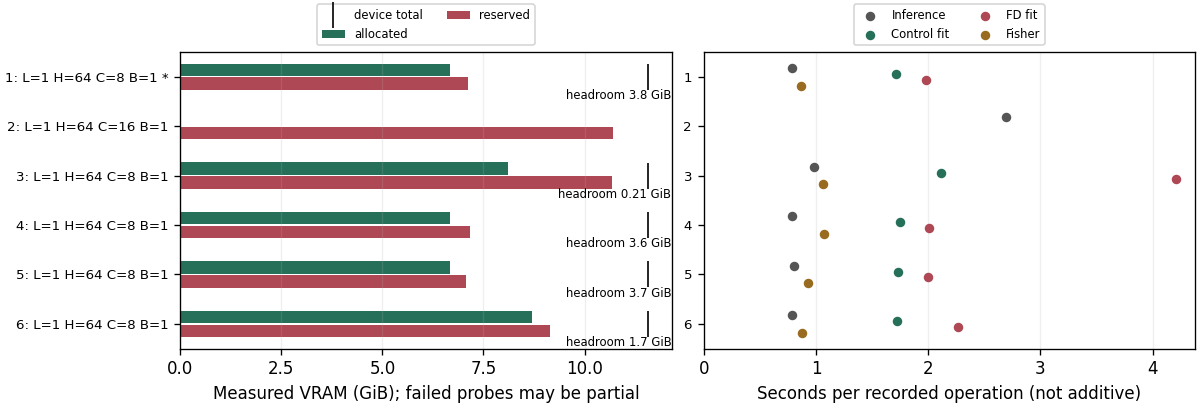

Forecast source (latest completed): forecast-4pairs-1200.


Paired replicas,New transitions / arm,Total active hours,Within 20 h
6,2400,38.9--55.7,false
4,1200,19.0--28.0,false


Stage,Low h,High h
2: Bootstrap,0.577,0.917
3: Development,5.85,9.3
4: Fresh pairs,12.1,16.8
5: Closeout,0.25,0.75
Reported total,19,28


Recorded budget fit: false. Total scope is as recorded, not inferred by adding phase estimates or concurrent probe charges.


Forecast includes shared bootstrap, development, 72 evaluation episodes per arm, sleep, and checkpoint I/O. One optimizer event and one eviction Fisher per new transition are assumed; larger sleep batches and skill rescue work need remeasurement. Ranges are engineering allowances, not confidence intervals.


Blockers: ["Frozen Qwen teacher did not demonstrate useful A skill in this small readiness pilot.", "Frozen RGB potential did not consistently rank success above far failure.", "Real-time inference/update pilot missed more than 10% of non-startup ...


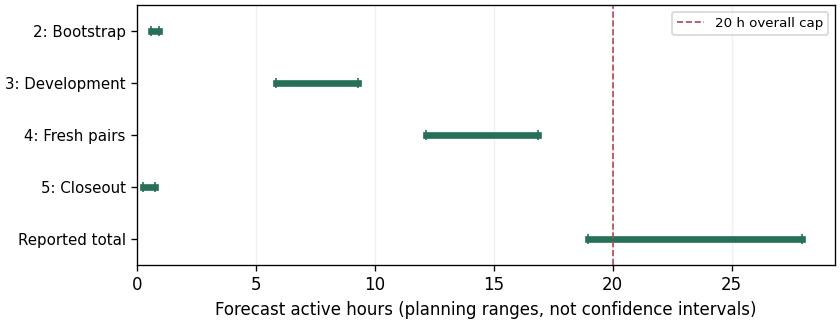

Fresh scope,Raw training frames / records (GB),Retain every full checkpoint (GB)
6 pairs x 2400,13.5,1.55e+03
4 pairs x 1200,4.67,393


Storage is a fresh-training projection, not a total allocation: development, evaluation video, and failed attempts add bytes. Keeping every transaction snapshot is not an admitted policy; bounded recovery checkpoints plus an append-only event journal/archive are needed before learning.


Audit,Check / metric,Value
Scene,source (latest completed),scene-ec88e89988aa; 3 archived unit(s)
Scene,limitations,"[""Privileged controller is not a teacher or student performance estimate."", ""Accelerated CPU feedback does not test wall-clock inference deadlines."", ""No physical calibration or hardware validation."", ""Frozen Qwen panel scoring belongs t..."
Scene,scene count,4
Scene,successes,1
Scene,accelerated,true
Scene,all feasible,false
Scene,diagnostic,PRIVILEGED scripted feasibility diagnostic; not teacher/student demonstrations
Scene,frozen evaluator status,pending_parent_RGB_only_scoring
Scene,hardware connected,false
Scene,reward panel truth verified,true


Probe,Recorded numerical checks
1,control_last_losses.data=8.15; control_last_losses.ewc=0.00561; control_last_losses.fd=0; control_last_losses.fisher_scale=0.000307; control_last_losses.kappa=3.07e-05; control_last_losses.ridge=0.00042; control_last_losses.total=8.16; c...
2,finite_action=true
3,control_last_losses.data=8.16; control_last_losses.ewc=0.00526; control_last_losses.fd=0; control_last_losses.fisher_scale=0.00028; control_last_losses.kappa=2.8e-05; control_last_losses.ridge=0.000381; control_last_losses.total=8.16; co...
4,control_last_losses.data=8.15; control_last_losses.ewc=0.0121; control_last_losses.fd=0; control_last_losses.fisher_scale=0.000632; control_last_losses.kappa=6.32e-05; control_last_losses.ridge=0.000833; control_last_losses.total=8.16; c...
5,control_last_losses.data=8.15; control_last_losses.ewc=0.0207; control_last_losses.fd=0; control_last_losses.fisher_scale=0.00114; control_last_losses.kappa=0.000114; control_last_losses.ridge=0.00144; control_last_losses.total=8.17; con...
6,control_last_losses.data=8.15; control_last_losses.ewc=0.00561; control_last_losses.fd=0; control_last_losses.fisher_scale=0.000307; control_last_losses.kappa=3.07e-05; control_last_losses.ridge=0.00042; control_last_losses.total=8.16; c...


Probe,Blocker / limitation,Recorded reason
2,oom,"CUDA out of memory. Tried to allocate 570.00 MiB. GPU 0 has a total capacity of 11.57 GiB of which 574.19 MiB is free. Including non-PyTorch memory, this process has 10.40 GiB memory in use. Of the allocated memory 9.76 GiB is allocated ..."
3,inadmissible,insufficient reserved GPU headroom


Archived artifacts: /home/evan/Documents/notebooks/amari-chenstov-updates/cache/numerical_experiment/picar

Readiness numbers are recorded diagnostics, not held-out student competence or sample savings. Missing role, language, fallback, or physical checks remain unverified. Top-0 is diagnostic-only. Strong sim-to-real claims require physical calibration. Forecast accounting must include evaluation, sleep, failed attempts, reporting and I/O, charged once; a budget extension requires approval.


In [ ]:
from numerical_experiment.picar.phase1_report import display_phase1
display_phase1(snapshot)

### Phase 1 Fix 1: Grounding and Online Readiness

The original run found an unvalidated action/reward interface and updates that blocked control. This repair checks native-model parity, clearer motor semantics and visual history, then cooperative scheduling. Original results remain above. These are engineering diagnostics, not STM learning results; the newest repair revision is shown without pooling attempts.

Scene,Native/split relative error,Parity,Mass on action digits,Native description
far_deadline_failure,0,True,1,"The red ball is located at the top center of the image, while the blue block is positioned at the bottom center. The path appears to be clear, as there are no obstacles directly in"
near_goal_not_success,0,True,1,"The red ball is located on the ground in front of the blue block. The path appears to be clear, as there are no obstacles directly in the way."
stopped_success,0,True,1,"The red ball is located on the ground in the center of the image, slightly to the right. The blue block is positioned behind the red ball, closer to the top edge of the image. The"
obstacle_collision,0,True,1,"The red ball is located at the top center of the image, approximately 0.5 units above the ground plane. The blue block is positioned on the ground plane, covering the bottom half o"


Role interface,Valid teacher outputs,Instruction contrasts,Visual reward ordering
legacy,True,False,False
grounded-low,True,False,False
grounded-visual-v2,True,True,False
generated-visual-v2,True,True,False


Teacher,Panel,Domain,Successes / episodes
grounded-visual-v2,development,A,0/2
grounded-visual-v2,development,B,0/2
generated-visual-v2,development,A,0/2
generated-visual-v2,development,B,0/2


History,Period (s),Cooperative,Fallbacks / non-startup,Fallback (%),Update handoffs,Deadline guide
4,0.75,False,4/24,16.7,0,False
4,0.75,True,0/20,0.0,6,True
4,1.00,False,2/17,11.8,0,False
4,1.00,True,0/15,0.0,4,True
4,1.25,False,0/12,0.0,0,True
4,1.25,True,0/13,0.0,2,True


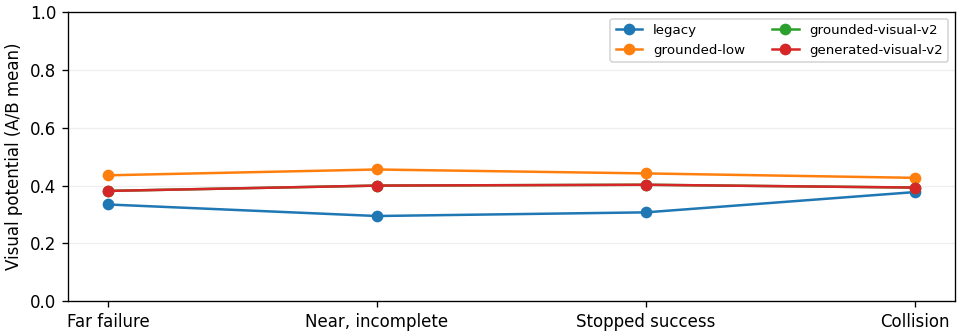

Repair compute: 5.5 active minutes. Later learning phases remain unstarted.
A competent language-responsive Qwen teacher is not validated on 20 fresh layouts.
Visual shaping potential is not validated; no-shaping remains an unselected versioned fallback.


Execution notes: Revision 2 corrected conflicting default-mission prompting; version 1 prompt remains available. A Tk rendering backend abort interrupted revision 2; completed units were preserved. Headless Agg rendering was enabled, then --resume verified/skipped completed diagnostics and retried the incomplete short control pilot.


In [ ]:
from numerical_experiment.picar.phase1_fix_report import display_repair
display_repair(snapshot)

### Phase 1 Fix 2: Dense Visual Rewards and Robot Workflow

The prior readiness checks used a completion probability and a potential difference, which did not reproduce the earlier robot's graded visual rewards. This repair generates explicit 0–10 scores, checks unobstructed approach before obstacle navigation, and audits the complete reward-to-return pipeline. Target contact is success; obstacle/wall contact is failure. Historical Fix 1 results remain above. These are readiness diagnostics, with no STM efficacy claim.

The initial Fix 2 attempt (`fix2-v1`) rejected valid JSON inside Markdown fences. Its raw responses and artifacts remain available; those rejected responses are not a navigation-performance estimate. The revised parser accepts one exact JSON fence while retaining strict values/keys. The revised timing pilot also masks retired recurrent predecessors.

Software acceptance,Result
passed,637 passed in 42.56s


Rubric,Panel,Valid scores,Absent/present,Correct approach pairs,Readiness guide
legacy,development,True,True,1/12,False
contact,development,True,True,5/12,False
contact,validation,True,True,8/12,False


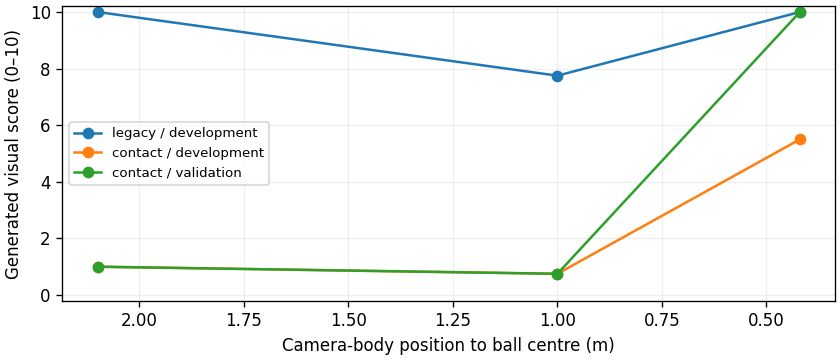

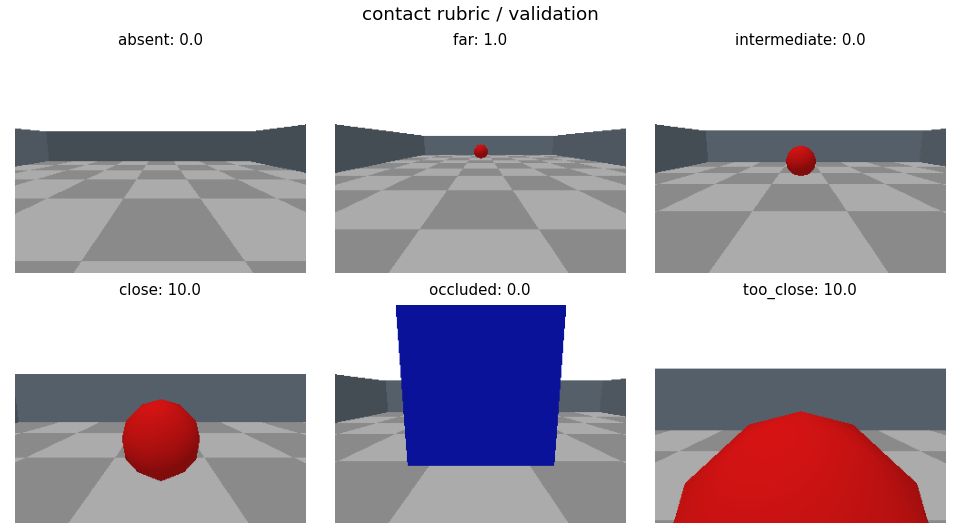

Teacher,Panel,Task,Domain,Successes / episodes
ported,development,Unobstructed ball,A,2/3
ported,development,Unobstructed ball,B,1/3
grounded,development,Unobstructed ball,A,0/3
grounded,development,Unobstructed ball,B,0/3
ported,development,Obstacle + ball,A,0/3
ported,development,Obstacle + ball,B,0/3
grounded,development,Obstacle + ball,A,0/3
grounded,development,Obstacle + ball,B,0/3


Teacher rollouts use accelerated physics for task diagnosis. Their success rates do not establish real-time Qwen control. Full real-time pipeline timing below uses the student.


Return bins,Tied progress pairs,Gradient ordering,Max log-weight rounding error,Selected
41,0,True,0.0439,True
81,0,True,0.0222,False
161,0,True,0.0112,False


Timing model context,Timing replay capacity,New/replay batch,Return bins,Physical control period (s)
4,8,1 / 1,41,1.0


Loss,Non-startup fallbacks,Updates,Retired records,Peak label backlog,Pending after drain,Total active seconds
replay_ewc,0/44,44,36,17,0,84.5
stm_fd,0/44,44,36,17,0,84.2


Conditional study,Total forecast (h),Fits 20-hour cap
6 pairs x 2400 observations/arm,37.7 to 47.1,False
4 pairs x 1200 observations/arm,27.9 to 33.5,False


Displayed totals add 986.2 minutes of earlier acceptance/profiling to the sealed forecast's repair ledger. Forecasts assume an optimizer event and eventual Fisher admission per new observation; fit wall times include cooperative waits, so the serial sum is conservative. They do not establish teacher/student competence or budget approval.


Requirement,Status
Causal instructions/countdown,implemented and tested
Contact semantics,CPU Bullet tests passed
Numeric rewards and return pipeline,implemented and audited
Pi and speech interfaces,injected/recorded-input acceptance passed; physical validation pending
Real-time service,"measured, including stopped labeling/drain; see limitations"
Retired sleep option,default-off; CPU acceptance passed


Fix 2 active compute: 17.9 min; all repair work: 31.1 min.
Generated visual scores or return resolution remain below the readiness guide.
Full obstacle-task Qwen competence is not validated on 20 fresh layouts.
The full study remains subject to resource review and Phase 2 student readiness.


In [ ]:
from numerical_experiment.picar.phase1_fix2_report import display_fix2
display_fix2(snapshot)

### Phase 1 Fix 3: Centering Rewards and Gradual Navigation

Fix 2 yielded useful straight approaches but no obstacle-task successes; recognition did not imply reliable spatial guidance. Fix 3 adds a small pan-discounted centering bonus and a broad-to-concentrated barrier curriculum. The teacher and evaluator remain frozen: easy demonstrations support one-time student distillation, then the student learns from its own experience. These bounded diagnostics are not an STM comparison. Only sealed completed units enter results; live progress is operational information.

Campaign: fix3-v1 (earlier attempt; revisions are not pooled).


Earlier attempt,Status,Completed units (sealed),Compute (min),Approach order fraction,Centering order fraction
fix3-v1,stopped; artifacts retained,8,4.412,0,1


Earlier raw panels, prompts and source snapshots remain in /home/evan/Documents/notebooks/amari-chenstov-updates/cache/numerical_experiment/picar/phase1/fix3-v1/units.


Campaign: fix3-v2 (revisions are not pooled).


Status,Completed units (sealed),Pending units,Active compute (s),Cumulative repair (s),Remaining estimate (s)
Fix 3: pilot complete,24,0,4828,7047,0


Context,Replay capacity,Return bins,Curriculum ramp
4,8,161,320 total intervals


Geometry density/blockage and separate alpha schedule


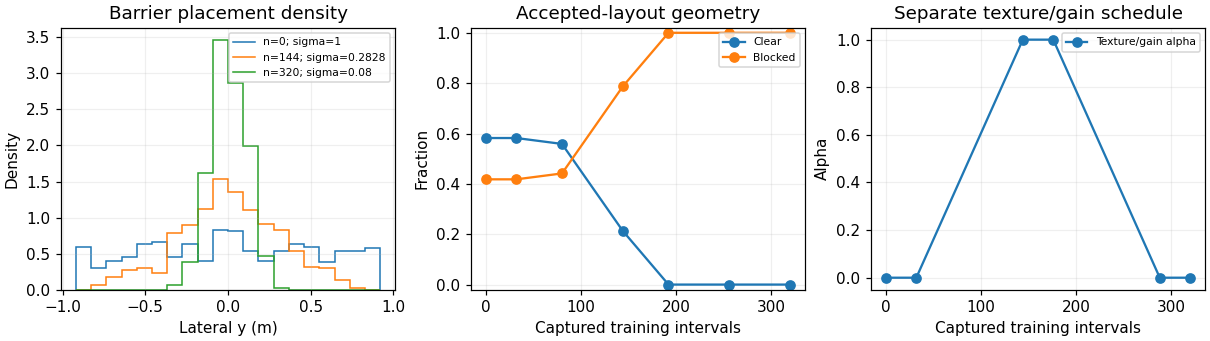

Blockage describes accepted layouts, not task success. Returning texture/gain alpha to A does not restore the initial easy placement distribution.


Reward components and contact sheet (pan in radians)


Split,Images,Centering order fraction,Approach order fraction,Absent ball scores zero
development,20,0.6667,0.6667,True
validation,20,0.3333,0.6667,True


split=validation; state=middle-center; seed=9411; proximity=1; centering=1; visible=True; pan_rad=0; centering_bonus=0.5; score=1.5,split=validation; state=middle-left; seed=9411; proximity=10; centering=1; visible=True; pan_rad=0; centering_bonus=0; score=10,split=validation; state=middle-edge; seed=9411; proximity=1; centering=0.2667; visible=True; pan_rad=0; centering_bonus=0.1333; score=1.133
split=validation; state=pan-centered; seed=9411; proximity=1; centering=1; visible=True; pan_rad=-0.3491; centering_bonus=0; score=1,split=validation; state=close; seed=9411; proximity=10; centering=1; visible=True; pan_rad=0; centering_bonus=0; score=10,split=validation; state=absent; seed=9411; proximity=0; centering=0; visible=False; pan_rad=0; centering_bonus=0; score=0

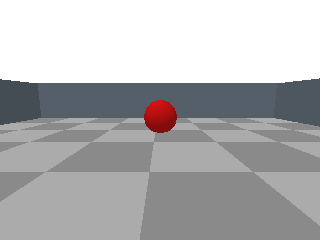
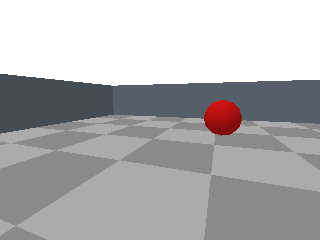
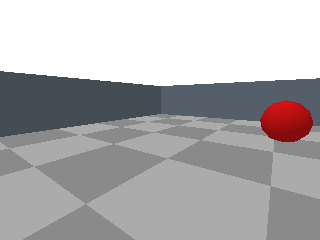
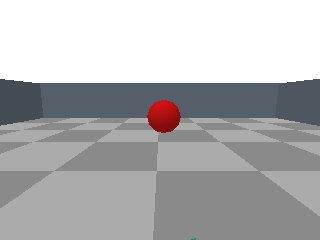
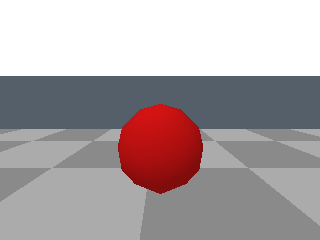
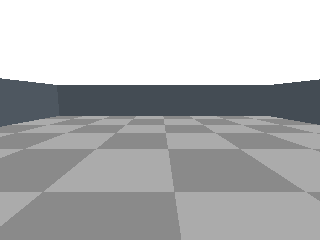

Frozen teacher results (not student learning)


Variant,Episodes,Success count / rate,Commands total,Unique actions,End reasons
centering,6,3/6 (50.0%),115,1,success: 3; collision: 3
ported,6,3/6 (50.0%),115,1,success: 3; collision: 3


Easy bootstrap and one-time student distillation


Transitions,Distillation initial KL,Distillation final KL,Executed teacher examples,Selected exploration SD
292,1.957,0.004125,247,4


Student pilot: fixed-panel pre/post evaluation, separately by difficulty and seed


Seed,Acquired transitions,Training episodes
193701,305,27


Seed,Checkpoint,Difficulty,Episodes,Success count / rate,Collision count / rate,Panel identity
193701,initial,easy,2,2/2 (100.0%),0/2 (0.0%),matched layout IDs
193701,final,easy,2,2/2 (100.0%),0/2 (0.0%),matched layout IDs
193701,initial,middle,2,2/2 (100.0%),0/2 (0.0%),matched layout IDs
193701,final,middle,2,2/2 (100.0%),0/2 (0.0%),matched layout IDs
193701,initial,hard,2,0/2 (0.0%),2/2 (100.0%),matched layout IDs
193701,final,hard,2,0/2 (0.0%),2/2 (100.0%),matched layout IDs


Before/after clips: checkpoint=initial; layout_id=195803; view=ego+topdown; checkpoint=final; layout_id=195803; view=ego+topdown

Seed,Acquired transitions,Training episodes
193702,300,23


Seed,Checkpoint,Difficulty,Episodes,Success count / rate,Collision count / rate,Panel identity
193702,initial,easy,2,2/2 (100.0%),0/2 (0.0%),matched layout IDs
193702,final,easy,2,2/2 (100.0%),0/2 (0.0%),matched layout IDs
193702,initial,middle,2,2/2 (100.0%),0/2 (0.0%),matched layout IDs
193702,final,middle,2,2/2 (100.0%),0/2 (0.0%),matched layout IDs
193702,initial,hard,2,0/2 (0.0%),2/2 (100.0%),matched layout IDs
193702,final,hard,2,0/2 (0.0%),2/2 (100.0%),matched layout IDs


Before/after clips: checkpoint=initial; layout_id=195803; view=ego+topdown; checkpoint=final; layout_id=195803; view=ego+topdown

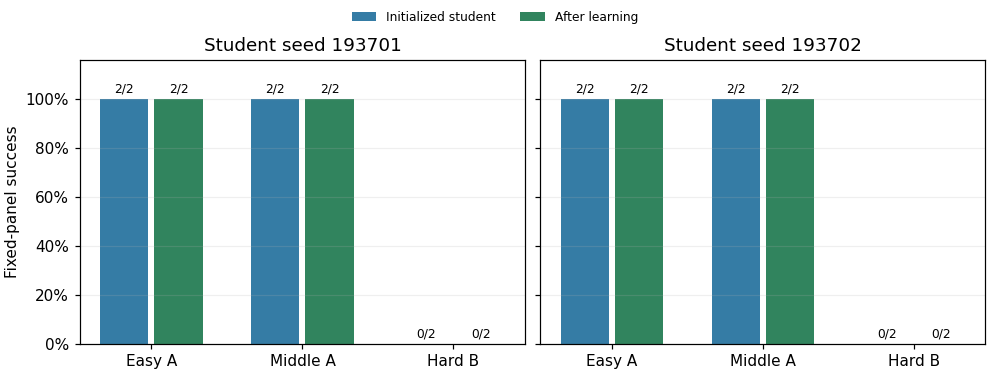

Fixed panels must retain identical layouts across checkpoints; missing layout IDs leave pairing unverified. Training success mixes learning with changing difficulty and is not an evaluation rate.


Readiness: diagnostic units recorded; completion alone does not establish student learning. Unresolved issues: pending / not recorded. No STM efficacy or physical-operation claim; stop at the resource/task check-in.


In [ ]:
from numerical_experiment.picar.phase1_fix3_report import display_fix3
display_fix3(snapshot)

### Phase 2: Initial Skill and Common Student Readiness

Before comparing FD, establish useful initial easy-A skill and common student trainability on B. Frozen Qwen need not solve the hard task. The baseline reuses the compatible Fix 3 bootstrap; its original counts and compute are excluded from new Phase 2 charges. Easy-A uses all 20 fixed layouts (192501--192520); hard-B uses the first 10. Clear and blocked paths are reported together. Two baseline student pilots (192101/192102) are bounded at 640 intervals each. The prior-study estimate is conservatively about 2.25 h; Phase 2 has a 5 h cap and ends at a check-in, not automatic Phase 3. Only sealed units supply results; live progress is operational information.

A later language audit exposed a saturated visual-to-LSTM projection. Separately versioned, parameter-free RMS rescues reuse the recorded demonstrations but rebuild their one-time initialization and Fisher. They test conditioning with FD disabled, not STM efficacy. All Phase 2 versions share the same five-hour cap.

Phase 2 campaign: readiness-v1; revisions are not pooled.


Status,Sealed units,Progress,Active unit,Active seconds,Remaining estimate (s),Settings
stopped,10,"{""step"": 8, ""target"": 13}",pending / not recorded,5460.62,pending / not recorded,pending / not recorded


Health unit,Normalization,Median |z|,|tanh(z)| > .99,Median derivative,Max derivative,epsilon
feature-health-v1,none,11.589,1,0,1.22786e-05,1e-06


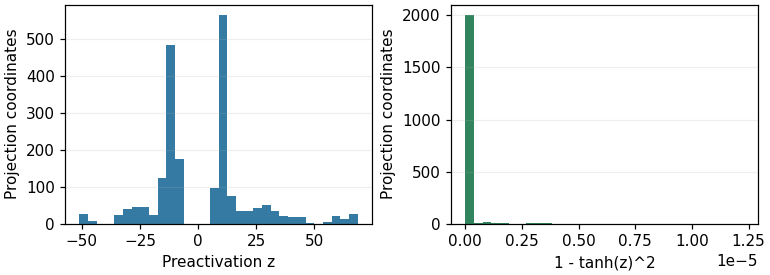

Phase 2 campaign: readiness-rms-v1; revisions are not pooled.


Status,Sealed units,Progress,Active unit,Active seconds,Remaining estimate (s),Settings
ready_for_checkin,14,"{""step"": 12, ""target"": 12}",pending / not recorded,6829.82,pending / not recorded,pending / not recorded


Health unit,Normalization,Median |z|,|tanh(z)| > .99,Median derivative,Max derivative,epsilon
feature_health-ca6d89089119,feature_rms,10.8267,1,0,0.000120044,1e-06


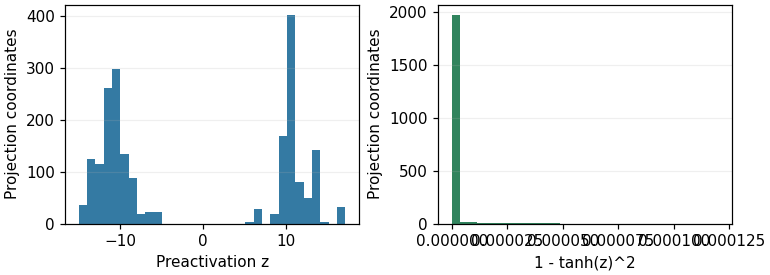

Health unit,Normalization,Median |z|,|tanh(z)| > .99,Median derivative,Max derivative,epsilon
feature_health-867583e65492,feature_and_projection_rms,0.935702,0,0.4622,0.999987,1e-06


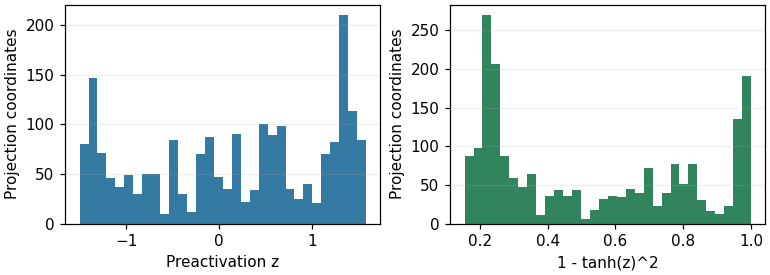

Asset,acquired_count,distinct_bootstrap_samples,retired_count,eligible_count
bootstrap,292,247,239,8
bootstrap,292,247,239,8


Historical baselines shown for comparison: not new runs and not pooled with rescue trajectories.


model,seed,easy_initial,easy_final,hard_initial,hard_final,source,new_trajectory,charged_again
original baseline,192101,7/20,7/20,0/10,0/10,/home/evan/Documents/notebooks/amari-chenstov-updates/cache/numerical_experiment/picar/phase2/readiness-v1/units/pilot-2bed313bb4fb,False,False
original baseline,192102,7/20,7/20,0/10,0/10,/home/evan/Documents/notebooks/amari-chenstov-updates/cache/numerical_experiment/picar/phase2/readiness-v1/units/pilot-c1fb39286264,False,False


Controller / seed,Checkpoint / level,Success,Collisions,Easy clear; blocked success,Coverage / pairing,Physical seconds (mean / n),Terminal geometry (mean)
feature_rms / 192101,initial / easy,7/20 (35.0%),13/20 (65.0%),7/11 (63.6%); 0/9 (0.0%); 0 unknown paths,20/20 expected seed IDs; 0 unexpected; 0 duplicates; matched seed IDs (n=20),10 / 20,clearance_m=0.7396 (n=20/20); heading_error_rad=-0.1519 (n=20/20)
feature_rms / 192101,initial / hard,0/10 (0.0%),10/10 (100.0%),n/a,10/10 expected seed IDs; 0 unexpected; 0 duplicates; matched seed IDs (n=10),4.947 / 10,clearance_m=1.368 (n=10/10); heading_error_rad=-0.08002 (n=10/10)
feature_rms / 192101,final / easy,7/20 (35.0%),13/20 (65.0%),7/11 (63.6%); 0/9 (0.0%); 0 unknown paths,20/20 expected seed IDs; 0 unexpected; 0 duplicates; matched seed IDs (n=20),10.01 / 20,clearance_m=0.7394 (n=20/20); heading_error_rad=-0.1514 (n=20/20)
feature_rms / 192101,final / hard,0/10 (0.0%),10/10 (100.0%),n/a,10/10 expected seed IDs; 0 unexpected; 0 duplicates; matched seed IDs (n=10),4.948 / 10,clearance_m=1.368 (n=10/10); heading_error_rad=-0.07987 (n=10/10)
feature_and_projection_rms / 192101,initial / easy,7/20 (35.0%),13/20 (65.0%),7/11 (63.6%); 0/9 (0.0%); 0 unknown paths,20/20 expected seed IDs; 0 unexpected; 0 duplicates; matched seed IDs (n=20),10 / 20,clearance_m=0.7395 (n=20/20); heading_error_rad=-0.1518 (n=20/20)
feature_and_projection_rms / 192101,initial / hard,0/10 (0.0%),10/10 (100.0%),n/a,10/10 expected seed IDs; 0 unexpected; 0 duplicates; matched seed IDs (n=10),4.952 / 10,clearance_m=1.368 (n=10/10); heading_error_rad=-0.07998 (n=10/10)
feature_and_projection_rms / 192101,final / easy,7/20 (35.0%),13/20 (65.0%),7/11 (63.6%); 0/9 (0.0%); 0 unknown paths,20/20 expected seed IDs; 0 unexpected; 0 duplicates; matched seed IDs (n=20),10.11 / 20,clearance_m=0.7377 (n=20/20); heading_error_rad=-0.1254 (n=20/20)
feature_and_projection_rms / 192101,final / hard,0/10 (0.0%),10/10 (100.0%),n/a,10/10 expected seed IDs; 0 unexpected; 0 duplicates; matched seed IDs (n=10),4.996 / 10,clearance_m=1.368 (n=10/10); heading_error_rad=-0.07681 (n=10/10)


Student seed,Recipe,Settings,Episodes,New acquired,Initialization
192101,feature_rms,"{""ridge"": 0.1, ""teacher_floor"": 0.001, ""transitions"": 640}",58,635,receipt archived
192101,feature_and_projection_rms,"{""ridge"": 0.1, ""teacher_floor"": 0.001, ""transitions"": 640}",53,623,receipt archived


Student seed,Recipe,Online updates,Sleep updates,Fallback counts,Timings (s)
192101,feature_rms,551,20,"{""inference_pending"": 6, ""policy"": 571, ""startup"": 58}","{""active_seconds"": 2480.876719156, ""checkpoint_seconds"": 862.637516459039, ""evaluation_seconds"": 632.6418323090111, ""fisher_seconds"": 82.65576650498406, ""fit_seconds"": 517.8367620860099, ""scoring_seconds"": 553.6478255790007, ""sleep_seconds"": 801.2939036139978}"
192101,feature_and_projection_rms,543,19,"{""episode_ended_before_command"": 1, ""inference_pending"": 7, ""policy"": 562, ""startup"": 53}","{""active_seconds"": 2468.954490447999, ""checkpoint_seconds"": 857.5163103760078, ""evaluation_seconds"": 638.6544840479964, ""fisher_seconds"": 81.34864336699138, ""fit_seconds"": 512.9313337299973, ""scoring_seconds"": 552.8492686969767, ""sleep_seconds"": 801.1016071600061}"


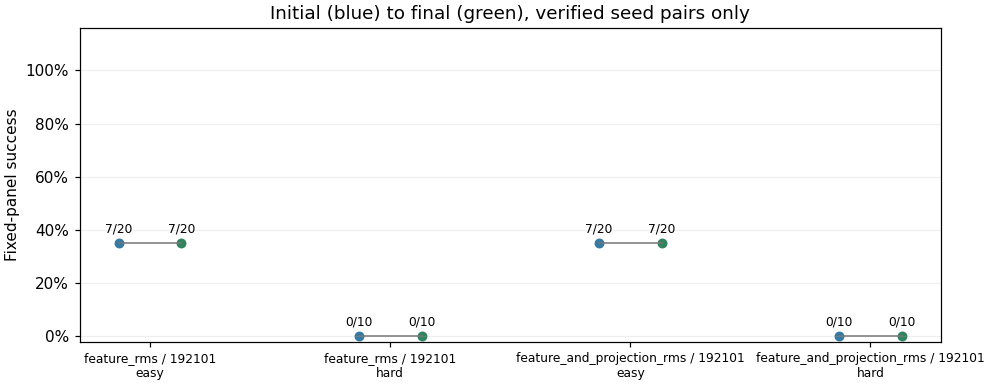

Success/collision counts are descriptive fixed-layout observations, not independent training trajectories or significance tests. Missing outcomes are unknown, not failures; terminal geometry is optional. The 70% teacher / 60% student / within-15-point easy-A guides are engineering guides, not significance thresholds.


Recorded controller clips, distinct from old scripted demos: controller=learned_student; checkpoint=initial; difficulty=easy; controller=learned_student; checkpoint=initial; difficulty=hard; controller=learned_student; checkpoint=final; difficulty=easy; controller=learned_student; checkpoint=final; difficulty=hard

Recorded controller clips, distinct from old scripted demos: controller=learned_student; checkpoint=initial; difficulty=easy; controller=learned_student; checkpoint=initial; difficulty=hard; controller=learned_student; checkpoint=final; difficulty=easy; controller=learned_student; checkpoint=final; difficulty=hard

Language responsiveness: four instruction means, not proof of instruction following; raw histories remain archived.


Instruction,Rows,Valid probability rows,Mean forward P,Mean left P,Mean right P,Argmax counts
forward,8,8,0.992154,0.00113149,0.00110597,drive-forward: 8
left,8,8,0.992154,0.00113149,0.00110597,drive-forward: 8
right,8,8,0.992154,0.00113149,0.00110597,drive-forward: 8
stop,8,8,0.992154,0.00113149,0.00110597,drive-forward: 8


Instruction,Rows,Valid probability rows,Mean forward P,Mean left P,Mean right P,Argmax counts
forward,8,8,0.991824,0.00117794,0.00115518,drive-forward: 8
left,8,8,0.991831,0.00117676,0.00115436,drive-forward: 8
right,8,8,0.991803,0.00118104,0.00115816,drive-forward: 8
stop,8,8,0.991593,0.00121322,0.00118673,drive-forward: 8


pairs,observations_per_arm,fd_cost_multiplier_scenario,training_processing_hours,evaluation_hours_at_pilot_panel_size,not_total_study_forecast
4,1200,1,7.79764,1.41255,True
4,1200,2,11.6965,1.41255,True
6,2400,1,23.3929,2.11883,True
6,2400,2,35.0894,2.11883,True


Field,Recorded
seconds_per_captured_interval,2.92411
phase2_active_seconds,12273.2
prior_study_seconds,8129.19
study_charged_seconds,20402.4
remaining_to_20h_seconds,51597.6
trainability_observed,False
fd_unmeasured,True
next_phase_authorized,False


Unit,Recorded
provenance,"{""archive_sha256"": ""eba33c888ba4c1e4ec033eb68cdda69bd5550bfccf1d245939b9e4a6ec22c512""}"
software,"{""passed"": true, ""test_result"": ""62 passed in 12.17s""}"
campaign,"{""next_phase_authorized"": false, ""status"": ""ready_for_checkin"", ""total_active_seconds"": 6829.820052154999, ""trainability_observed"": false}"
closeout,"{""next_phase_authorized"": false, ""passed"": true, ""status"": ""reviewed"", ""test_result"": ""124 Phase 2 unit tests passed; 35 final reporting tests passed""}"


Forecasts are conditional operational estimates, not FD or sample-efficiency measurements. FD multipliers are scenarios, not measurements; later development and closeout cost extra. Readiness completion does not authorize Phase 3 or physical operation; stop for the resource/task check-in.


In [ ]:
from numerical_experiment.picar.phase2_report import display_phase2
display_phase2(snapshot, notebook_dir='/home/evan/Documents/notebooks/amari-chenstov-updates/numerical_experiment/picar')

### Phase 3: Common Learning and FD Calibration

Calibrate shared learning scales and FD resolution before selecting a retention-qualified comparison. Easy-A retention and hard-B acquisition use the same fixed 20-A/10-B development panels before and after each candidate. Repeated layouts are measurements, not independent training replicas; versions and seeds are not pooled. Selection is not a presumed FD win or a sample-savings result: fresh paired Phase 4 trajectories are still required. Only sealed units enter results; live progress is operational information.

Phase 3 campaign: solver-fix2-v1; versions are not pooled.


Campaign,Status,Completed trajectories,Active unit,Active progress,Budget remaining (s),Remaining estimate (s),Phase 3 active (s),Study charge (s),Unit progress,Sealed units
solver-fix2-v1,stopped,0,recorded-e80c418e1dcd,recorded solver comparison: 88/128,31772,pending / not recorded,pending / not recorded,65109.4,88/128,0


Phase 3 campaign: solver-fix2-v2; versions are not pooled.


Campaign,Status,Completed trajectories,Active unit,Active progress,Budget remaining (s),Remaining estimate (s),Phase 3 active (s),Study charge (s),Unit progress,Sealed units
solver-fix2-v2,recorded solver comparison,0,recorded-9813bb3e40e0,recorded solver comparison: 8/128,30958.5,pending / not recorded,pending / not recorded,65922.9,8/128,0


Phase 3 campaign: development-v1; versions are not pooled.


Campaign,Status,Completed trajectories,Active unit,Active progress,Budget remaining (s),Remaining estimate (s),Phase 3 active (s),Study charge (s),Unit progress,Sealed units
development-v1,stopped,pending / not recorded,pending / not recorded,pending / not recorded,pending / not recorded,pending / not recorded,10388.2,31107.8,pending / not recorded,9


... (7 outputs left out)

name,seed,fd_strength,ridge,old_gap_average,old_gap_endpoint,new_gain_average,new_gain_endpoint,checkpoints,panel_resolution
control_ridge_0.1,193101,0,0.1,0.183014,0.25,0,0,3,0.05
control_ridge_0.03,193101,0,0.03,0.1832,0.25,0,0,3,0.05
control_ridge_0.3,193101,0,0.3,0.161146,0.15,0,0,3,0.05


Check,Recorded,Status
probe,"{""data_gradient_norm"": 5.697513580322266, ""fd_convergence_pass"": true, ""new_observations"": 0, ""probe_age_weight"": 1.0, ""probe_count"": 1, ""probe_seed"": 193033, ""scratch_state_restored"": true, ""selected_fd_step"": 0.01}",True
probe / fd_strength_rows,"{""fd_strength"": 0.8177253700955127, ""target_gradient_ratio"": 0.01}",pending / not recorded
probe / fd_strength_rows,"{""fd_strength"": 8.177253700955125, ""target_gradient_ratio"": 0.1}",pending / not recorded
probe / fd_strength_rows,"{""fd_strength"": 81.77253700955127, ""target_gradient_ratio"": 1.0}",pending / not recorded
probe / fit_cost_rows,"{""fd_strength"": 0.0, ""median_update_seconds"": 0.26525458693504333, ""optimizer_steps"": 2, ""repetitions"": 3}",pending / not recorded
probe / fit_cost_rows,"{""fd_strength"": 8.177253700955125, ""median_update_seconds"": 0.3799242079257965, ""optimizer_steps"": 2, ""repetitions"": 3}",pending / not recorded
probe / FD resolution 1,"{""epsilon"": 0.005, ""gradient_norm"": 0.0696873813867569, ""ltm_gradient_norm"": 0.031167836859822273, ""penalty"": 0.020175941288471222, ""seconds"": 0.058811332999539445, ""stm_gradient_norm"": 0.062328945845365524}",True
probe / FD resolution 1,"{""cosine_to_previous"": 0.9999999403953552, ""epsilon"": 0.01, ""gradient_norm"": 0.06967514753341675, ""ltm_gradient_norm"": 0.031161107122898102, ""penalty"": 0.02017253264784813, ""seconds"": 0.05736174999947252, ""stm_gradient_norm"": 0.062318626791238785}",True
probe / FD resolution 1,"{""cosine_to_previous"": 0.9999995231628418, ""epsilon"": 0.02, ""gradient_norm"": 0.0696251168847084, ""ltm_gradient_norm"": 0.031133996322751045, ""penalty"": 0.020158644765615463, ""seconds"": 0.05773990399939066, ""stm_gradient_norm"": 0.062276244163513184}",True


Asset,acquired_count,distinct_bootstrap_samples,retired_count,eligible_count,normalization
bootstrap-6d4c1a77310c,292,247,239,8,feature_and_projection_rms


Candidate / seed,Settings,New captured,Timings (s)
control_retention_repair / 193101,"{""action_variance"": 16.0, ""exploration_std"": 4.0, ""fd_step"": 0.01, ""fd_strength"": 0.0, ""lr"": 0.001, ""pi0"": 0.01, ""ridge"": 0.3, ""steps"": 1, ""tau"": 2.8375266913896}",623,"{""active_seconds"": 2725.7794069599995, ""checkpoint_seconds"": 993.912571166994, ""evaluation_seconds"": 878.6811288229974, ""fisher_seconds"": 80.01192456800709, ""fit_seconds"": 521.6478720739997, ""scoring_seconds"": 509.5224951680002, ""sleep_seconds"": 779.5596500290007}"
control_ridge_0.3 / 193102,"{""action_variance"": 1.0, ""exploration_std"": 8.0, ""fd_step"": 0.01, ""fd_strength"": 0.0, ""lr"": 0.003, ""pi0"": 0.025, ""ridge"": 0.3, ""steps"": 2, ""tau"": 2.8375266913896}",623,"{""active_seconds"": 3128.6835153770007, ""checkpoint_seconds"": 1246.6008523419905, ""evaluation_seconds"": 1162.6602195380055, ""fisher_seconds"": 76.4509918390113, ""fit_seconds"": 630.1708071889989, ""scoring_seconds"": 485.94139519200144, ""sleep_seconds"": 785.8867898829958}"


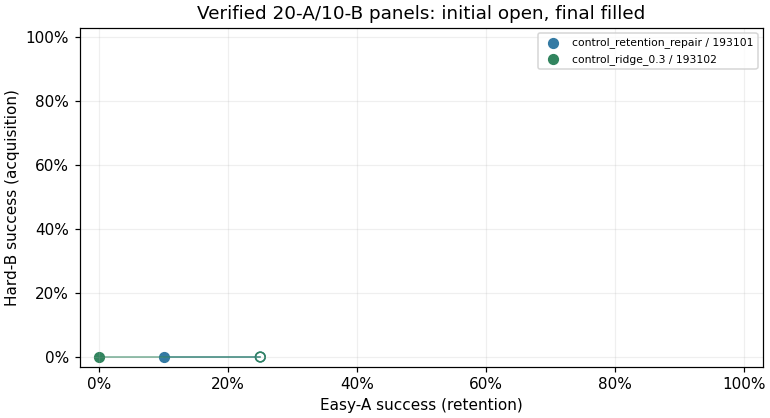

Candidate / seed,Checkpoint,Level,Success
control_retention_repair / 193101,midpoint,easy,5/20 (25.0%)
control_retention_repair / 193101,midpoint,hard,0/10 (0.0%)
control_ridge_0.3 / 193102,midpoint,easy,0/20 (0.0%)
control_ridge_0.3 / 193102,midpoint,hard,0/10 (0.0%)


Field,Recorded
selected_control,control_ridge_0.3
selected_fd,Not selected
control_learning_observed,False
retention_matched,Not evaluated
ready_to_propose_confirmation,False
development_replica_count,2
retention_tolerance,0.05
control_retention_limit,0.1
retention_status,pending / not recorded
next_phase_authorized,False


name,seed,fd_strength,ridge,old_gap_average,old_gap_endpoint,new_gain_average,new_gain_endpoint,checkpoints,panel_resolution
control_ridge_0.1,193101,0.0,0.1,0.183014,0.25,0,0,3,0.05
control_ridge_0.03,193101,0.0,0.03,0.1832,0.25,0,0,3,0.05
control_ridge_0.3,193101,0.0,0.3,0.161146,0.15,0,0,3,0.05
control_retention_repair,193101,0.0,0.3,0.0353933,0.15,0,0,3,0.05
control_ridge_0.3,193102,0.0,0.3,0.185393,0.25,0,0,3,0.05


Recorded old_gap values are A retention loss; new_gain values are B acquisition. Comparison differences are FD minus the same-seed control, not independent replicas.


Not run because of the shared development budget; these are omissions, not failed trajectories. Admission also retains the recorded safety and closeout allowances.


Candidate,"Estimated minutes, before safety margin","Remaining minutes, excluding closeout",Reason
fd_retention_ratio_01,69.7588,63.8313,shared Phase 3 admission allowance


... (5 outputs left out)

Preselected candidate clips: control_ridge_0.3 / 193102


Recorded controller clips, distinct from old scripted demos: controller=learned_student; checkpoint=initial; difficulty=easy: pending / not recorded; controller=learned_student; checkpoint=initial; difficulty=hard: pending / not recorded; controller=learned_student; checkpoint=midpoint; difficulty=easy; controller=learned_student; checkpoint=midpoint; difficulty=hard; controller=learned_student; checkpoint=final; difficulty=easy; controller=learned_student; checkpoint=final; difficulty=hard

Unit,Recorded
software,"{""passed"": true, ""test_result"": ""79 passed in 153.69s (0:02:33)""}"
provenance,"{""archive_sha256"": ""3dd0bdf572c35e23f74dc8738fdc3cff508128f5c185d4f1163f0eb87efcdf72""}"


Development is not confirmation; panel repetition adds no independent training replicas. A weighting effective count is not an iid sample count. Missing evidence stays unverified; sample savings are unavailable until fresh paired Phase 4 trajectories.


In [ ]:
from numerical_experiment.picar.phase3_report import display_phase3
display_phase3(snapshot, notebook_dir='/home/evan/Documents/notebooks/amari-chenstov-updates/numerical_experiment/picar')

#### Historical Phase 3 Closeout

Phase 3 (`development-retention-v1`): ready_for_checkin. Common-control learning remains unresolved; this is not a negative FD result. FD passed the numerical checks, but no paired FD efficacy trajectory was completed. Its full trajectory was not admitted within the remaining development budget.

| Candidate / seed | Easy A, start to end | Hard B, start to end | Average A loss (pp) |
|---|---|---|---:|
| control_ridge_0.1 / 193101 | 25% to 0% | 0% to 0% | 18.3 |
| control_ridge_0.03 / 193101 | 25% to 0% | 0% to 0% | 18.3 |
| control_ridge_0.3 / 193101 | 25% to 10% | 0% to 0% | 16.1 |
| control_retention_repair / 193101 | 25% to 10% | 0% to 0% | 3.5 |
| control_ridge_0.3 / 193102 | 25% to 0% | 0% to 0% | 18.5 |

Each row is one development trajectory, not a pooled estimate. Average A loss is initial success minus exposure-weighted mean success between the three measured checkpoints (trapezoidal interpolation), in percentage points; positive means deterioration. Retention during the stream and final retention can differ.

| Selection | Recorded |
|---|---|
| selected_control | control_ridge_0.3 |
| selected_fd | Not selected |
| retention_matched | Not evaluated |
| next_phase_authorized | False |
| reason | Common learning, matched retention, or two-seed replication remains unresolved; preserve the frontier. |

These are descriptive development panels, not independent training replicas; sample savings are unavailable until fresh paired Phase 4 trajectories. Review calibration, retention qualifications and measured cost at the next check-in; no automatic Phase 4 execution follows from artifact completion.

### Phase 3 Fix 1: Stationary Initialization and Bulk Fisher

The earlier Phase 3 results remain historical. This separately versioned repair fits fixed, whole-episode train/validation sets with STM neutral, then builds an equal-weight model-score Fisher at the accepted anchor. Repeated passes and synthetic score draws are not new observations; validation guides development, not confirmation. Only sealed results are plotted. Committed live counters are operational progress; missing results are **pending**, never zero.

The repair has its own **8--10 active-hour planning range and 10-hour ceiling**, separate from the prior study ledger (about 10.719 h); the historical 20-hour target does not limit this repair.

1. Coverage / data size. Counts distinguish acquired transitions, usable histories and episodes. Coverage includes all available collected histories, not just a fitted prefix and the fixed validation panel. Dominant actions are recorded teacher argmax labels; outcome bars retain failures. Overlapping contexts are not iid.


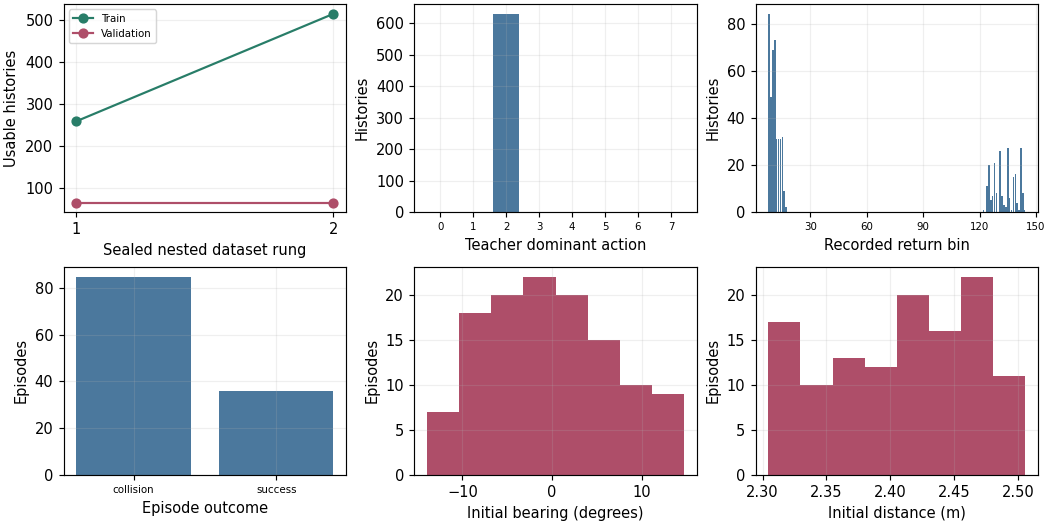

Acquired,New acquisitions,Usable train / validation,Episodes,Successes,Degenerate teacher coverage,Control ranges
752,460,515 / 65,121,36,True,"{""drive_mps_range"": [0.0, 0.19880834147778026], ""steering_rad_range"": [0.0, 0.0]}"


2. Fixed-set optimization. NLL is the declared joint return/action negative log likelihood; KL measures divergence from recorded teacher actions. Lower is better on the same fixed histories; validation is diagnostic, not fresh confirmation. Finite or flat loss alone does not prove an MLE.


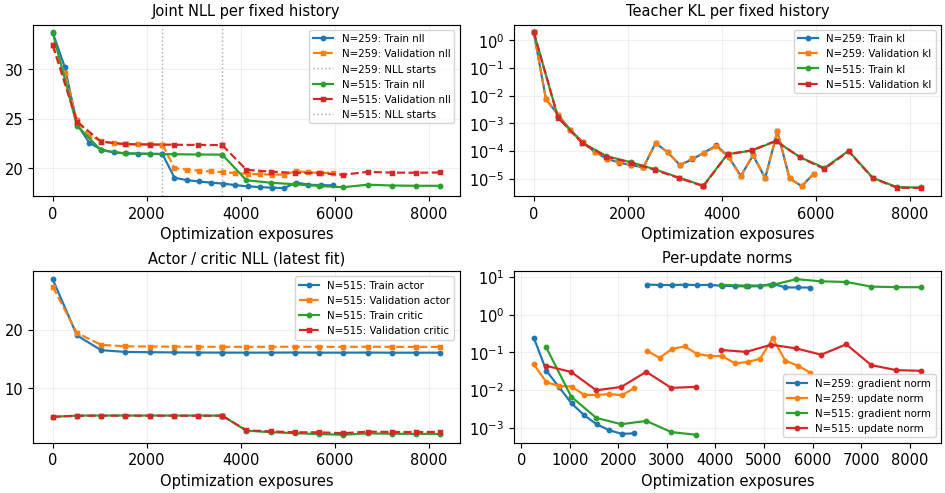

Readiness,Recorded
Declared fit rule,True
Optimization,True
Data adequacy,unresolved
Fisher numerical / stability,True / False
Recorded cautions,validation_selected_earlier_epoch; NLL_fit_increased_validation_teacher_KL; inspect_initial_A_capability


3. Bulk Fisher / local quadratic. D0 is the average per-history model Fisher diagonal; accumulated information is N D0, not a second Fisher. More label draws reduce Monte Carlo error, not increase data count. Relative diagonal disagreement needs absolute error near zero. NLL remainder subtracts its first-order term; exact predictive KL is a separate curvature reference, not proof of LAN or exact diagonal agreement.


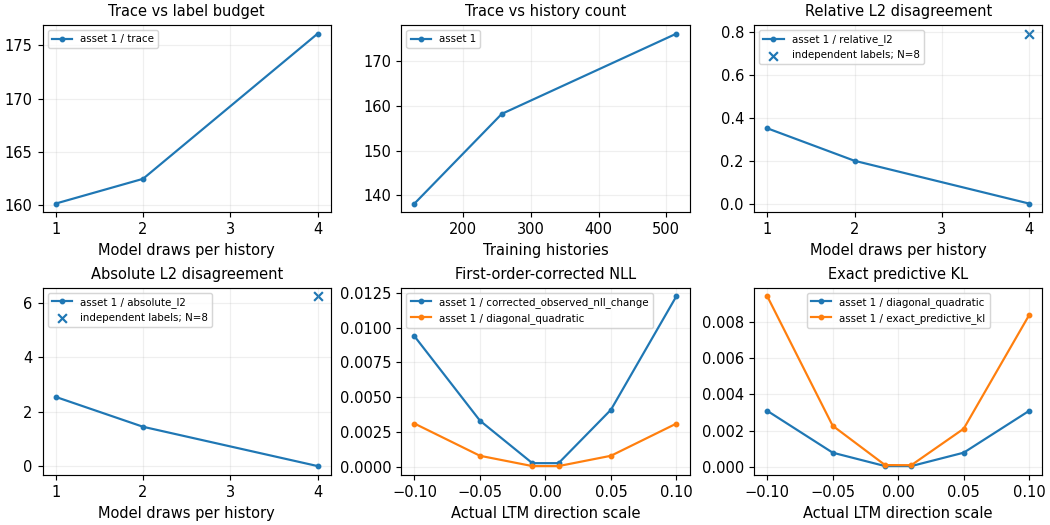

Histories,Reference draws / history,Primary trace,Reference trace,Relative diagonal L2 difference,Combined repair h
515,16,176.103,200.318,0.24687,7.19205


This independent higher-draw estimate is a reference, not truth. It isolates model-label Monte Carlo sensitivity on the same training histories and anchor; the primary Fisher and all learning comparisons are unchanged.


4. Initial capability / paired progression. A success is retained initial capability; B success is acquisition on held-out layouts. Only explicit Boolean outcomes enter rates. Repeated panels are not independent training replicas. Development cannot establish confirmatory sample savings.


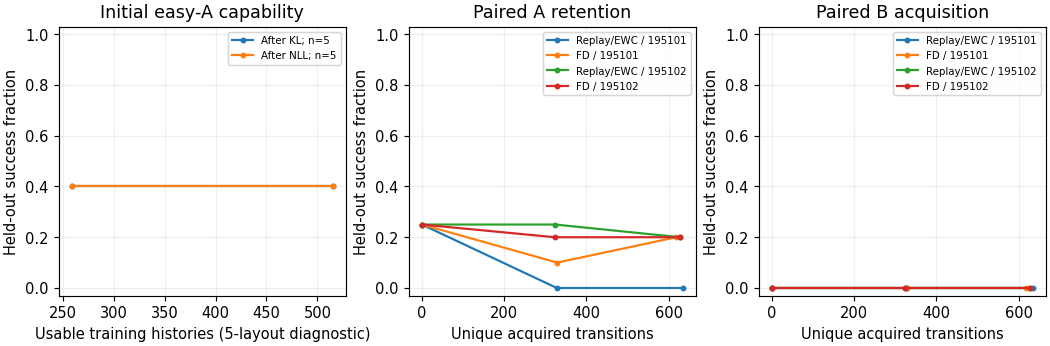

Checkpoint,Domain,Success / evaluated
distillation,easy,5 / 20
accepted_nll,easy,5 / 20
accepted_nll,hard,0 / 10


Seed,Method,Incoming intervals,A successes: initial -> final,B successes: initial -> final,Active min
195101,Replay/EWC,634,5/20 -> 0/20,0/10 -> 0/10,51.6
195101,STM FD,619,5/20 -> 4/20,0/10 -> 0/10,43.3
195102,Replay/EWC,628,5/20 -> 4/20,0/10 -> 0/10,43.5
195102,STM FD,628,5/20 -> 4/20,0/10 -> 0/10,45.6


Only completed development trajectories appear in this table. A and B use their fixed held-out layout panels; initial and final successes are counts, not training returns. Active minutes include evaluation. Missing trajectories remain pending.


Five-layout rung panels have 20-percentage-point resolution; they are development diagnostics, not fresh significance tests or the full selected panels.


selected_learning_rate,selected_optimizer_steps,selected_fd_step,fd_convergence_pass
0.003,1,0.01,True


Recorded controller clips, distinct from old scripted demos: controller=learned_student; checkpoint=initial; difficulty=easy; controller=learned_student; checkpoint=initial; difficulty=hard

Recorded controller clips, distinct from old scripted demos: controller=learned_student; checkpoint=initial; difficulty=easy; controller=learned_student; checkpoint=initial; difficulty=hard

Recorded controller clips, distinct from old scripted demos: controller=learned_student; checkpoint=initial; difficulty=easy; controller=learned_student; checkpoint=initial; difficulty=hard

Recorded controller clips, distinct from old scripted demos: controller=learned_student; checkpoint=initial; difficulty=easy; controller=learned_student; checkpoint=initial; difficulty=hard

Detailed histories, settings and journals remain in the sealed artifacts; missing panels and readiness stay pending.


In [ ]:
from numerical_experiment.picar_initialization.report import display_diagnostics
display_diagnostics(snapshot, notebook_dir='/home/evan/Documents/notebooks/amari-chenstov-updates/numerical_experiment/picar')

## Development

Retention matching and recipe selection use development artifacts only. A selected recipe and fresh-run authorization are unavailable until explicitly recorded.

## Fresh Learning

Held-out B success measures acquisition. A failure increase measures loss of initial capability. Curves use unique new transitions, not replay exposures; smoke units are excluded.

In [ ]:
figure = report.plot_learning(snapshot)
display(figure) if figure is not None else print('Fresh held-out paired trajectories pending.')
effect = report.paired_failure_summary(snapshot)
display(pd.DataFrame([effect])) if effect['n_pairs'] else print('Paired failure effect unavailable: no complete scientific pairs.')

Fresh held-out paired trajectories pending.


Paired failure effect unavailable: no complete scientific pairs.


## Efficiency

A target needs two consecutive measured checkpoints meeting capability and retention gates. Interpolate only in observed brackets on the outward ramp/B hold. f is the fraction of new samples saved; c is the operational compute ratio; S=f/c. Half the experience at twice the compute gives S=0.25. Censored draws stay visible. No efficiency estimate is produced without supported crossings and recorded operational costs.

## Behavior and Mechanisms

Common preselected-seed clips show synchronized ego/top-down views with actual timestamps and controls. A separately selected failure gallery must be labeled. Missing media does not block scalar analysis.

In [ ]:
from IPython.display import HTML
display(HTML(report.media_links(snapshot)))

Stored behavior media links; missing clips remain explicitly labeled.

#### Historical Closeout Before Phase 3 Fix 2

Phase 3 Fix 1: The fit's declared readiness rule passed; optimization, data, Fisher and capability evidence remain distinct. Data adequacy: unresolved. Fisher stability: unresolved. Initial capability: recorded panels, not an automatic readiness pass. Teacher argmax-action coverage remained degenerate; fitting more histories did not establish diverse demonstrations. 4 sealed development trajectories are descriptive, not confirmation. The recorded comparison is not retention matched. Every completed pilot ended at zero hard-B successes; useful new-task learning is not established.

No sample-savings claim is supported by this development repair. Review fixed-set fitting, demonstration coverage, bulk-Fisher stability and initial capability separately before choosing further work. A budget stop is not scientific rejection; more data is warranted only by the diagnostics.

Endpoint A successes, one result per completed development trajectory: Replay/EWC 0/20, 4/20; STM FD 4/20, 4/20. Before confirmation, prioritize a separately versioned diagnostic of steering coverage and successful exploration; the present pilots do not isolate the acquisition bottleneck.

Stop for review; no automatic Phase 4 or physical motion.

### Phase 3 Fix 2: Curvature-Aware Updates and Solver Cost

The historical one-step explicit/recentered solver reported zero EWC penalty in 2,134/2,170 events. This exposed a solver blind spot, not the cause of every retention or navigation failure. The repair preserves the recurrent centered information summary: a centered penalty can act through curvature while its initial gradient is zero. No archived-score estimator is added. Compare two one-step recipes and three proximal steps for quality and measured cost, then use one selected recipe for four paired development trajectories. Recorded-history forks are not counterfactual robot rollouts; development is not confirmation. Both live conditions use the same trainable STM/LTM banks, replay, diagonal EWC and ridge; FD adds the age-weighted STM sensitivity penalty. Only sealed results enter plots. Both early and late segments restart from the common pre-stream initializer; the late segment is not a historical continuation or a restored late-policy checkpoint. Committed live counters are incomplete operational progress; missing values remain pending. The separate ceiling is nine additional active compute hours. Full derivations remain in plan19.md; full traces remain in linked artifacts.

Reporting campaign: **solver-fix2-v3** (versions are not pooled).

v1 diagnostic halt before live admission: RecordedRun.evaluate used _batch(row, validationpool), trimming recurrent context instead of using the frozen full holdout. v1 validation/selection is superseded and is not pooled with v2 science or v3 science. Sealed v1 artifacts remain preserved; all attempts share the same nine-hour Fix 2 ceiling. v2 stopped when lagged updates generated a nonfinite model output during retirement. v3 classifies this as a failed numerical candidate and gives all methods one common step-size reduction. Its unchanged completed proximal measurements are explicitly referenced with source seals, not counted as extra replicas. The two attempts carry 1,500 seconds into the same nine-hour budget, leaving 30,900 seconds for v3.


Declared recipes (plan settings, not measured outcomes). Live-gradient second moment only; no first-moment momentum. Ridge is proximal at the current center in all recipes; only lagged_1 delays its EWC center.


Recipe,Steps/event,EWC,Ridge,Plan alpha / beta2 / epsilon
proximal_1,1,centered proximal,current center; proximal,.003 / .999 / 1e-8
lagged_1,1,lagged explicit,current center; proximal,.003 / .999 / 1e-8
proximal_3,3,centered proximal,current center; proximal,.003 / .999 / 1e-8


Recorded comparison: same held-out pools, conditional on historical behavior; not live efficacy replicas.


Method,Alpha,Status,Events,Old NLL change,Live NLL change
Prox 1 / Replay/EWC,0.003,complete,128,+8.354,-5.466
Prox 1 / FD,0.003,complete,128,+10.837,-5.532
Lag 1 / FD,0.003,numerical_failure,12,pending / not recorded,pending / not recorded
Lag 1 / Replay/EWC,0.003,numerical_failure,13,pending / not recorded,pending / not recorded
Prox 3 / Replay/EWC,0.003,complete,128,+7.364,-4.830
Prox 3 / FD,0.003,complete,128,+9.523,-4.502
Prox 1 / Replay/EWC,0.001,complete,128,+10.541,-4.870
Prox 1 / FD,0.001,complete,128,+9.155,-5.040
Lag 1 / FD,0.001,numerical_failure,7,pending / not recorded,pending / not recorded
Lag 1 / Replay/EWC,0.001,numerical_failure,7,pending / not recorded,pending / not recorded


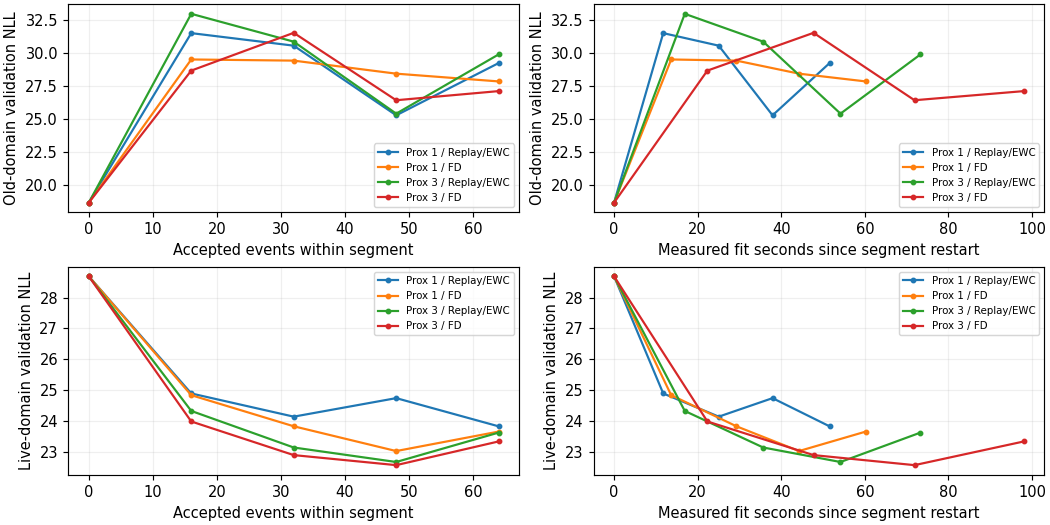

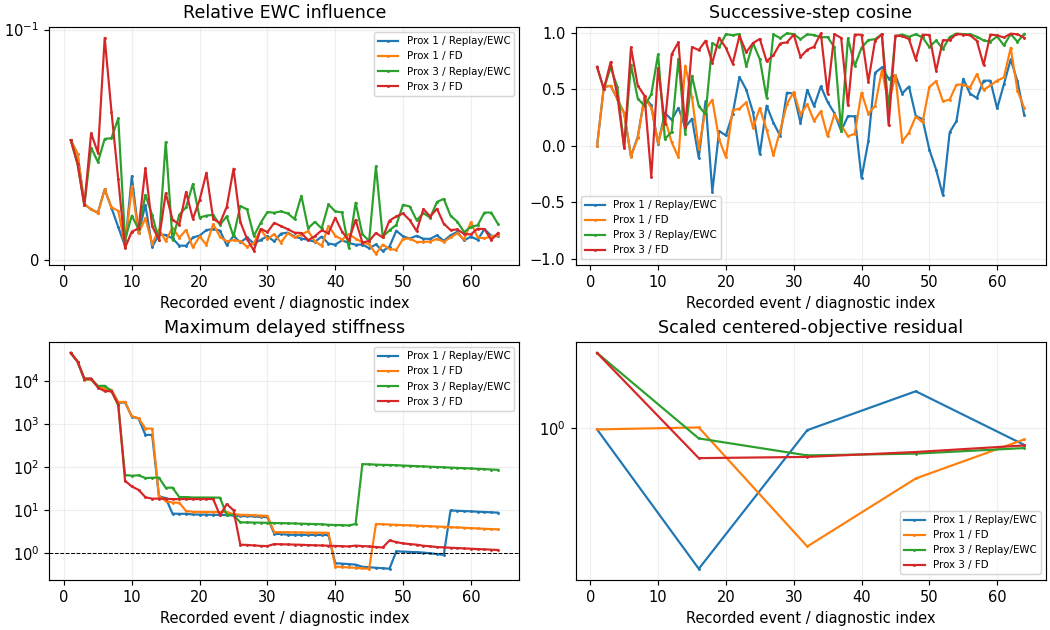

Timing and selection. Isolated GPU execution and online blocking are distinct; overlapping timers are not summed. Per-event mean/median/p95 exclude initial warm-up and extra-gradient diagnostic events under the recorded timing policy. All-event fit seconds and quality-versus-compute include charged diagnostics. Missing GPU telemetry remains unavailable; cost ratios use measured mean time for the same condition/alpha, never step counts. Torch peak is allocated tensor memory; device residency also includes reserved pools and CUDA overhead.


Method / alpha,Mean ms/event,P95 ms/event,GPU mean ms/event,Cost / Prox 1,Torch peak GiB
proximal_1 / replay_ewc / alpha=0.003,794.39,1005.86,795.43,1.00,3.60
proximal_1 / stm_fd / alpha=0.003,922.17,1182.92,923.41,1.00,4.72
lagged_1 / stm_fd / alpha=0.003,744.62,1123.47,745.72,0.81,4.50
lagged_1 / replay_ewc / alpha=0.003,665.22,969.55,666.18,0.84,3.50
proximal_3 / replay_ewc / alpha=0.003,1135.31,1411.91,1136.45,1.43,3.60
proximal_3 / stm_fd / alpha=0.003,1516.24,1933.15,1517.59,1.64,4.72
proximal_1 / replay_ewc / alpha=0.001,796.21,1003.46,797.30,1.00,3.60
proximal_1 / stm_fd / alpha=0.001,921.23,1176.75,922.45,1.00,4.72
lagged_1 / stm_fd / alpha=0.001,739.00,1128.85,740.10,0.80,4.50
lagged_1 / replay_ewc / alpha=0.001,642.83,980.16,643.82,0.81,3.50


Selected solver,Selected alpha,Reason,Candidate,stable,runs,old_gap,mean_seconds,live_nll
proximal_3,0.001,"Among finite completed methods within 0.1 old-domain NLL of best retention, choose the fastest within 0.05 live NLL of best; review curves and stability before live admission.",pending / not recorded,pending / not recorded,pending / not recorded,pending / not recorded,pending / not recorded,pending / not recorded
pending / not recorded,pending / not recorded,pending / not recorded,proximal_1,True,2,9.84765,0.858718,23.7325
pending / not recorded,pending / not recorded,pending / not recorded,lagged_1,False,2,pending / not recorded,pending / not recorded,pending / not recorded
pending / not recorded,pending / not recorded,pending / not recorded,proximal_3,True,2,9.80971,1.32592,23.4717


Selected-solver live development: four trajectories planned (two paired seeds), not six solver campaigns. Boolean fixed-layout outcomes only; repeated panels are not independent training replicas. The progress forecast extrapolates 48-interval live checks plus sealed Fix 1 evaluation cost, then uses completed pilot times as available. Its 0.75--1.5 planning multiplier is not a confidence interval and counts an unfinished pilot in full until completion.


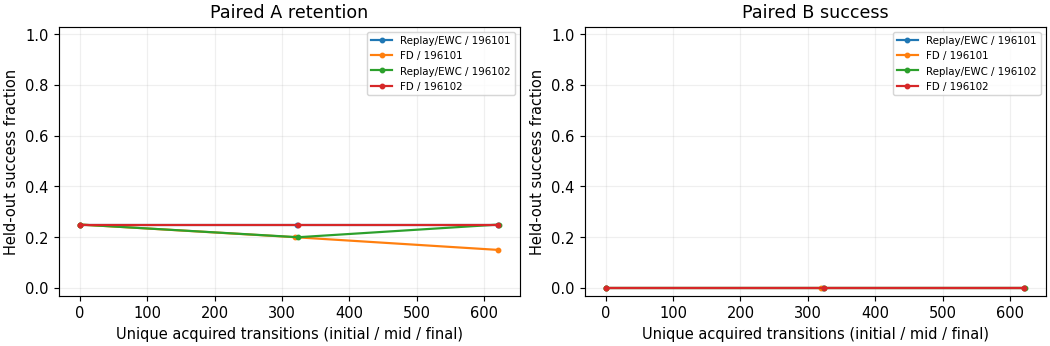

Seed,Method,Acquired,A initial / mid / final,B initial / mid / final,Wall / fit min
196101,Replay/EWC,621,5/20 / 5/20 / 5/20,0/10 / 0/10 / 0/10,43.5 / 13.4
196101,FD,621,5/20 / 4/20 / 3/20,0/10 / 0/10 / 0/10,49.8 / 16.8
196102,Replay/EWC,622,5/20 / 4/20 / 5/20,0/10 / 0/10 / 0/10,45.0 / 14.0
196102,FD,621,5/20 / 5/20 / 5/20,0/10 / 0/10 / 0/10,49.3 / 17.7


Seed / method,Mean / p95 fit s,Max actor lease wait s,Deadline misses,Non-startup fallback commands,Acquired / pilot h
196101 / Replay/EWC,1.438 / 3.822,0.446,3,3,856.8
196101 / FD,1.775 / 4.200,0.455,3,3,747.8
196102 / Replay/EWC,1.485 / 4.058,0.452,0,0,830.0
196102 / FD,1.847 / 4.530,0.446,1,1,756.5


Recorded controller clips, distinct from old scripted demos: controller=learned_student; checkpoint=final; difficulty=easy; controller=learned_student; checkpoint=final; difficulty=hard

Recorded controller clips, distinct from old scripted demos: controller=learned_student; checkpoint=final; difficulty=easy; controller=learned_student; checkpoint=final; difficulty=hard

Recorded controller clips, distinct from old scripted demos: controller=learned_student; checkpoint=final; difficulty=easy; controller=learned_student; checkpoint=final; difficulty=hard

Recorded controller clips, distinct from old scripted demos: controller=learned_student; checkpoint=final; difficulty=easy; controller=learned_student; checkpoint=final; difficulty=hard

25 scalar summaries and full traces (expand the HTML artifact links).

In [ ]:
from numerical_experiment.picar_solver_repair import report as solver_report
solver_snapshot = solver_report.load_report('/home/evan/Documents/notebooks/amari-chenstov-updates/cache/numerical_experiment/picar/phase3/solver-fix2-v3')
solver_report.display_diagnostics(solver_snapshot, notebook_dir='/home/evan/Documents/notebooks/amari-chenstov-updates/numerical_experiment/picar')

#### Training Reward Review (2026-11-16)

**Training rewards only.** Frozen A/B evaluations saved no Qwen reward scores. No images were rescored and no training or episodes were rerun for this review. Early/middle/late are thirds of the 640-interval training budget, assigned by episode reset exposure; they are not initial/mid/final frozen-model tests. Clear/blocked means the saved straight-to-target path test at reset, not A/B: both types can occur during the continuously changing curriculum.

Curves average episodes within each replica, then average the available replicas equally. Terminal reward stays in the cumulative curve after an episode ends; ended episodes are not silently dropped. Counts are shown because some groups are small. These are descriptive training summaries, not paired causal effects or confidence intervals.

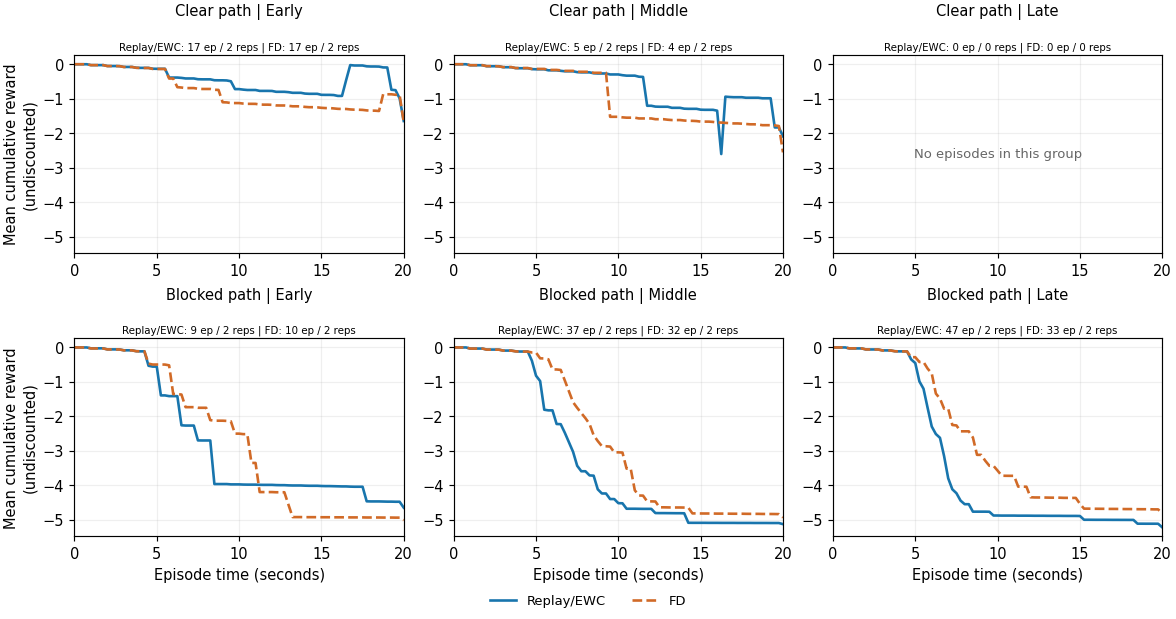

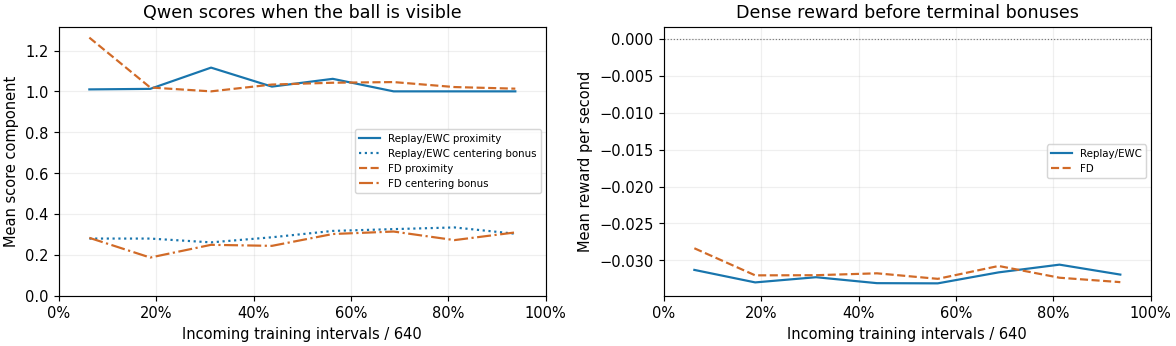

Method,Goals / episodes,Collisions / episodes,Visible-ball proximity = 1/10
Replay/EWC,3/115,98/115,98.4%
FD,1/96,71/96,96.8%


Reward per saved interval is r = 0.01 * score * elapsed_seconds - 0.04 * elapsed_seconds + terminal_bonus. Bonuses are +10 for success, -5 for collision and -1 for timeout. A far, centered ball scoring 1.5 therefore earns -0.025 per second before the terminal bonus. The learner uses full completed-episode discounted returns, not one-step Bellman/TD targets. Curves above show undiscounted earned reward, not return-to-go. Flat proximity scores support a weak shaping hypothesis, but do not by themselves prove distance miscalibration. Larger collision penalties are not an evident first fix: collisions already dominate these totals. A higher cumulative training curve can reflect later collisions or timeouts rather than reaching the ball; it is not evidence of hard-task mastery.


In the saved greedy evaluation decisions, forward had the largest action probability 100.0% of the time; 0/2734 commands exceeded 5 degrees of absolute steering. Reused initial panels are included, not treated as independent replicas. This is consistent with an inherited straight-driving policy, not proof that steering never occurred during exploratory training. A useful next hypothesis is insufficient coherent, rewarded detours: independent action noise need not produce successful multi-step turns. Probability-weighted left/right actions can also cancel steering; that is a mechanism to test, not an established cause here.


In [ ]:
from numerical_experiment import picar_reward_review
picar_reward_review.display_review(solver_snapshot)

## Conclusion

Phase 3 Fix 2: Recorded selection: proximal_3; alpha=0.001. Among finite completed methods within 0.1 old-domain NLL of best retention, choose the fastest within 0.05 live NLL of best; review curves and stability before live admission.

12 sealed recorded-data forks (4 numerical failures) and 4 sealed development pilots.

**Numerical repair:** EWC changed the first-step proposal in 256/256 recorded events for the selected recipe. This demonstrates curvature use, not successful retention or nonlinear convergence. A zero initial centered gradient is no longer an EWC blind spot.

**Cost:** selected-recipe isolated updates cost 1.43--1.65x one-step proximal updates across the two objectives. Whole live-run costs appear separately above.

FD and Replay/EWC share trainable STM/LTM banks, replay, EWC and ridge; FD adds the STM sensitivity penalty. Inherited penalty strengths were not freshly retention-matched under this solver, so these pilots do not isolate FD efficacy at equal retention.

**Live development:** endpoint held-out capability (A = initial/easy task, B = hard task). Initial/midpoint results and measured costs are in the preceding table.

| Seed | Method | Final A | Final B |
|---|---|---:|---:|
| 196101 | Replay/EWC | 5/20 | 0/10 |
| 196101 | FD | 3/20 | 0/10 |
| 196102 | Replay/EWC | 5/20 | 0/10 |
| 196102 | FD | 5/20 | 0/10 |

No completed pilot succeeded on its endpoint hard-task panel. The numerical repair therefore does not yet establish hard-task acquisition or FD efficacy. Better exploration/demonstration coverage remains a hypothesis for a separately agreed next step, not a diagnosed cause.

**Scope:** two development seeds sharing one initializer cannot establish fresh significance, retention equivalence or sample savings. Recorded-history forks are conditional diagnostics, not counterfactual navigation replicas. Stop for review; no automatic Phase 4 or physical motion.